# Assignment 5A – SVM for Handwritten Digit Classification (0–9)

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns

In [31]:
df = pd.read_csv('Digits.csv')
print(df.shape)
df.head(2)

(1797, 65)


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63,digit
0,0,0,5,13,9,1,0,0,0,0,...,0,0,0,6,13,10,0,0,0,0
1,0,0,0,12,13,5,0,0,0,0,...,0,0,0,0,11,16,10,0,0,1


In [32]:
# The last column is the label
X = df.drop(columns=['digit'])
y = df['digit']

print('Classes:', np.unique(y))
print('Class distribution:\n', y.value_counts().sort_index())

Classes: [0 1 2 3 4 5 6 7 8 9]
Class distribution:
 digit
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64


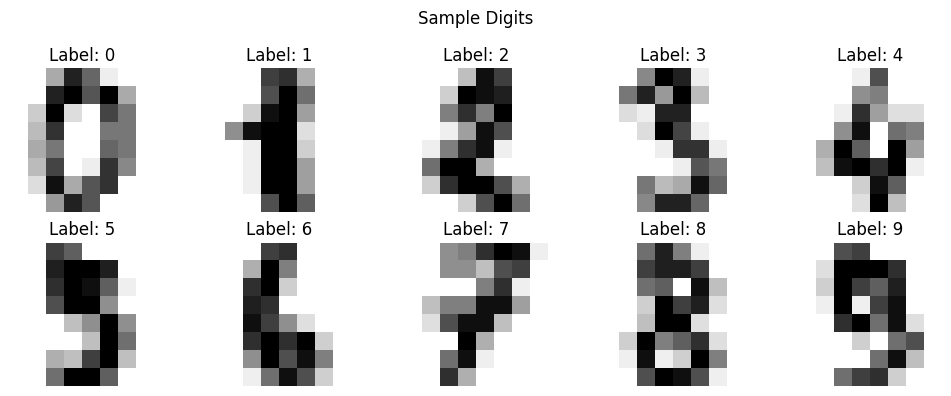

In [40]:
# Visualise a few sample digits
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in zip(range(10), axes.flat):
    image_vals = X[y == digit].iloc[0]
    ax.imshow(image_vals.values.reshape(8, 8), cmap='gray_r')
    ax.set_title(f'Label: {digit}')
    ax.axis('off')
plt.suptitle('Sample Digits')
plt.tight_layout()
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

In [ ]:
# Train SVM with RBF kernel
svm = SVC(kernel='rbf', C=10, gamma='scale', random_state=42)
svm.fit(X_train, y_train)

y_pred = svm.predict(X_test)
print(f'Accuracy: {accuracy_score(y_test, y_pred):.4f}\n')
print(classification_report(y_test, y_pred))

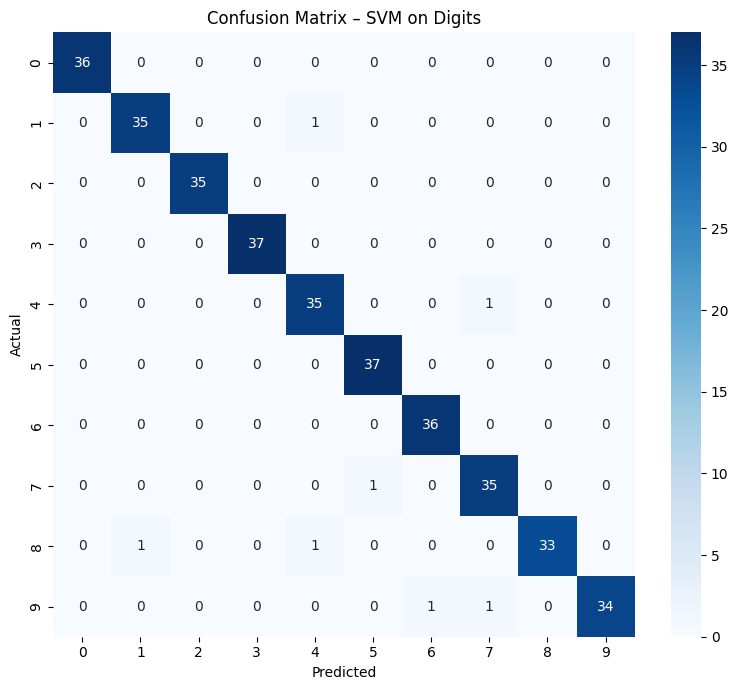

In [43]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=True, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix – SVM on Digits')
plt.tight_layout()
plt.show()

In [ ]:
# Display a test image with its predicted and actual digit.
plt.imshow(X_test[0].reshape(8, 8), cmap='gray')
plt.title(f'Predicted: {y_pred[0]}, Actual: {y_test[0]}')
plt.axis('off')
plt.show()